In [1]:
import pandas as pd

df = pd.read_csv('../runs/08_revenue_over_time.csv')

df["month"] = pd.to_datetime(df["month"])

print(df)

        month  order_count    revenue  average_order_value
0  2016-09-01            1     134.97               134.97
1  2016-10-01          265   40325.11               152.17
2  2016-12-01            1      10.90                10.90
3  2017-01-01          750  111798.36               149.06
4  2017-02-01         1653  234223.40               141.70
5  2017-03-01         2546  359198.85               141.08
6  2017-04-01         2303  340669.68               147.92
7  2017-05-01         3546  489338.25               138.00
8  2017-06-01         3135  421923.37               134.58
9  2017-07-01         3872  481604.52               124.38
10 2017-08-01         4193  554699.70               132.29
11 2017-09-01         4150  607399.67               146.36
12 2017-10-01         4478  648247.65               144.76
13 2017-11-01         7289  987765.37               135.51
14 2017-12-01         5513  726033.19               131.69
15 2018-01-01         7069  924645.00               130.

In [3]:
beginning_of_2017 = df[df['month'] == pd.Timestamp('2017-01-01')].iloc[0].to_dict()
end_of_2017 = df[df['month'] == pd.Timestamp('2017-12-01')].iloc[0].to_dict()
beginning_of_2018 = df[df['month'] == pd.Timestamp('2018-01-01')].iloc[0].to_dict()

beginning_of_analysis = df.iloc[0].to_dict()
end_of_analysis = df.iloc[-1].to_dict()

print('Revenue increase - all time (%): ', round((end_of_analysis['revenue'] - beginning_of_analysis['revenue']) * 100 / beginning_of_analysis['revenue'], 2))
print('Revenue increase - 2017 (%): ', round((end_of_2017['revenue'] - beginning_of_2017['revenue']) * 100 / beginning_of_2017['revenue'], 2))
print('Revenue increase - 2018 - analysis end (%): ', round((end_of_analysis['revenue'] - beginning_of_2018['revenue']) * 100 / beginning_of_2018['revenue'], 2), '\n')

print('Order count increase - all time (%): ', round((end_of_analysis['order_count'] - beginning_of_analysis['order_count']) * 100 / beginning_of_analysis['order_count'], 2))
print('Order count increase - 2017 (%): ', round((end_of_2017['order_count'] - beginning_of_2017['order_count']) * 100 / beginning_of_2017['order_count'], 2))
print('Order count increase - 2018 - analysis end (%): ', round((end_of_analysis['order_count'] - beginning_of_2018['order_count']) * 100 / beginning_of_2018['order_count'], 2), '\n')

print('AOV increase - all time (%): ', round((end_of_analysis['average_order_value'] - beginning_of_analysis['average_order_value']) * 100 / beginning_of_analysis['average_order_value'], 2))
print('AOV increase - 2017 (%): ', round((end_of_2017['average_order_value'] - beginning_of_2017['average_order_value']) * 100 / beginning_of_2017['average_order_value'], 2))
print('AOV increase - 2018 - analysis end (%): ', round((end_of_analysis['average_order_value'] - beginning_of_2018['average_order_value']) * 100 / beginning_of_2018['average_order_value'], 2))

Revenue increase - all time (%):  621205.95
Revenue increase - 2017 (%):  549.41
Revenue increase - 2018 - analysis end (%):  -9.31 

Order count increase - all time (%):  635000.0
Order count increase - 2017 (%):  635.07
Order count increase - 2018 - analysis end (%):  -10.16 

AOV increase - all time (%):  -2.17
AOV increase - 2017 (%):  -11.65
AOV increase - 2018 - analysis end (%):  0.95


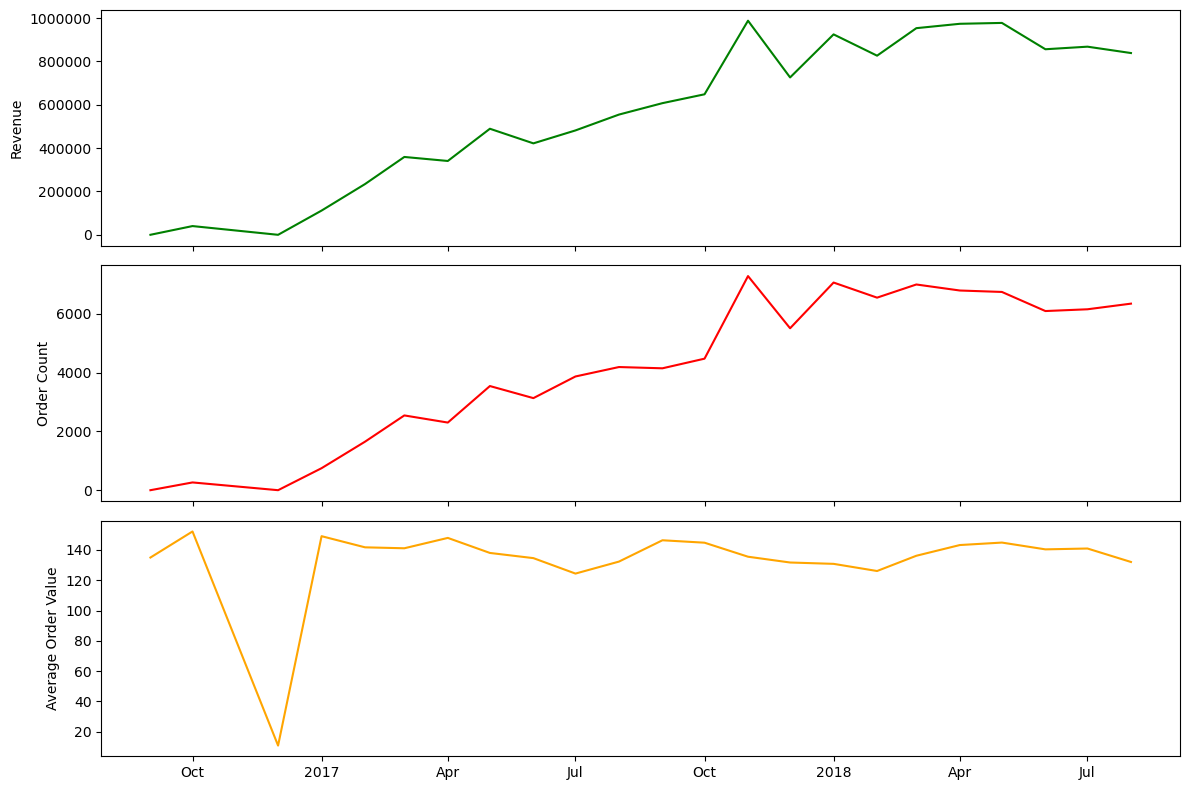

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, axes = plt.subplots(
    3,
    1,
    sharex=True,
    figsize=(12,8)
)
ax_revenue = axes[0]
ax_order_count = axes[1]
ax_aov = axes[2]

ax_revenue.ticklabel_format(style="plain", axis="y")

ax_revenue.plot(df["month"], df["revenue"], color="green")
ax_order_count.plot(df["month"], df["order_count"], color="red")
ax_aov.plot(df["month"], df["average_order_value"], color="orange")

ax_revenue.set_ylabel("Revenue")
ax_order_count.set_ylabel("Order Count")
ax_aov.set_ylabel("Average Order Value")

locator = mdates.AutoDateLocator()
formatter = mdates.ConciseDateFormatter(locator)

ax_aov.xaxis.set_major_locator(locator)
ax_aov.xaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()